# 🚗 Car Insurance Claim Prediction: explained step by step

**The question we are answering:** given details about a policyholder and their car, how likely is it that they will make an insurance claim?

- The answer we want to predict is the column **`claim_status`**: `1` = the person made a claim, `0` = no claim.
- Because the answer is one of two classes, this is a **binary classification** problem.
- The data has **58,592 policies** (rows) and **41 columns** (details about the policy, customer and car).

### The road map

| Part | What we do | Why |
|---|---|---|
| 1 | Load and look at the data | Know what we have before touching it |
| 2 | Check data quality | Missing values and duplicates can break a model |
| 3 | Understand the target | Is "claim" common or rare? This changes how we judge the model |
| 4 | Exploratory Data Analysis (EDA) | Find which columns seem related to claims |
| 5 | Feature extraction | Turn text such as `250Nm@2750rpm` into numbers |
| 6 | Feature selection | Keep only the columns that are useful |
| 7 | Encoding | Convert text (Yes/No, model names) into numbers |
| 8 | Train/test split | Keep some data hidden to test honestly |
| 9 | Train 3 models | Decision Tree, Random Forest, XGBoost |
| 10 | Evaluate and pick the best | Compare the models fairly |
| 11 | Save the model | So the web app can use it |
| 12 | The Streamlit app | A web page to try predictions |

**How to use this notebook:** put `Insurance claims data.csv` in the same folder as this notebook, then use **Restart, then Run All**. Read the explanation above each code cell before running it.

## Part 1: Setup and loading the data

### Step 1.1: Import the libraries
A *library* is a toolbox someone else wrote so we don't have to start from nothing.

| Library | What we use it for |
|---|---|
| `pandas` | Tables of data (a "DataFrame" is a table, like Excel inside Python) |
| `numpy` | Fast maths on numbers |
| `matplotlib` and `seaborn` | Drawing charts |
| `scikit-learn` (`sklearn`) | Splitting data, models, and scoring |
| `xgboost` | A powerful model (XGBoost) |
| `joblib` | Saving a trained model to a file |

`warnings.filterwarnings("ignore")` hides yellow warning messages so the output stays clean. When something goes wrong and you are debugging, remove that line to see the warnings again.

If you get `ModuleNotFoundError`, a library is missing. Install it in a terminal, for example `python -m pip install xgboost`.

In [1]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score)

RANDOM_STATE = 42   # a fixed 'seed' so that random steps give the same result every run

### Step 1.2: Display settings
By default pandas hides columns when a table is wide. These settings tell it to show **all columns** and to use a wider screen, so we never miss one. `sns.set_style("whitegrid")` gives charts a light grid background.

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)
sns.set_style("whitegrid")

### Step 1.3: Load the data
`pd.read_csv(...)` reads a CSV file and returns a DataFrame, which we call `df`.

If you see `FileNotFoundError`, Python can't find the file. Make sure the CSV is in the same folder as this notebook, and that the name in `CSV_PATH` matches exactly (including spaces and capital letters).

In [3]:
CSV_PATH = "Insurance claims data.csv"   # change this if your file has a different name or location
df = pd.read_csv(CSV_PATH)
df.head(3)

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,steering_type,turning_radius,length,width,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
0,POL045360,9.3,1.2,41,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
1,POL016745,8.2,1.8,35,C2,27003,C1,M9,Diesel,200Nm@1750rpm,97.89bhp@3600rpm,i-DTEC,2,No,Yes,No,Yes,Yes,Drum,1498,4,Manual,Electric,4.9,3995,1695,1051,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0
2,POL007194,9.5,0.2,44,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0


### Step 1.4: How big is the data, and what is in it?
- `df.shape` gives `(rows, columns)`.
- `df.info()` lists each column, how many values are filled in (**non-null**), and the **data type** (`int64`/`float64` = numbers, `str`/`object` = text).

Look at the data types carefully. Columns such as `is_esc` hold the text "Yes"/"No", and `max_torque` holds text like `250Nm@2750rpm`. A model can only work with numbers, so these will need converting later.

In [4]:
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (58592, 41)
<class 'pandas.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  str    
 1   subscription_length               58592 non-null  float64
 2   vehicle_age                       58592 non-null  float64
 3   customer_age                      58592 non-null  int64  
 4   region_code                       58592 non-null  str    
 5   region_density                    58592 non-null  int64  
 6   segment                           58592 non-null  str    
 7   model                             58592 non-null  str    
 8   fuel_type                         58592 non-null  str    
 9   max_torque                        58592 non-null  str    
 10  max_power                         58592 non-null  str    
 11  engine_type                       58592 non-null  s

## Part 2: Data quality checks

### Step 2.1: Missing values and duplicates
- **Missing values** (`NaN`) are blanks. Many models crash or give wrong answers if blanks are left in.
- **Duplicate rows** are exact copies of another row. They make the model see the same example twice and can leak information between the training and test sets.

`df.isna().sum().sum()` adds up every blank in the whole table. `df.duplicated().sum()` counts repeated rows. We want **0** for both, and we also check that every `policy_id` is unique.

In [5]:
print("Missing values in the whole table:", df.isna().sum().sum())
print("Duplicate rows                   :", df.duplicated().sum())
print("Unique policy_id values          :", df["policy_id"].nunique(), "of", len(df))

Missing values in the whole table: 0
Duplicate rows                   : 0
Unique policy_id values          : 58592 of 58592


✅ **Good news:** the data has no blanks and no duplicates, so no cleaning is needed here. (If there had been, we would use `df.dropna()`, `df.fillna(...)` or `df.drop_duplicates()`.)

## Part 3: Understand the target (`claim_status`)

### Step 3.1: How many people made a claim?
Always look at your target first. `value_counts()` counts each value, and `normalize=True` turns the counts into percentages.

claim_status
0    54844
1     3748
Name: count, dtype: int64 

claim_status
0    93.6
1     6.4
Name: proportion, dtype: float64


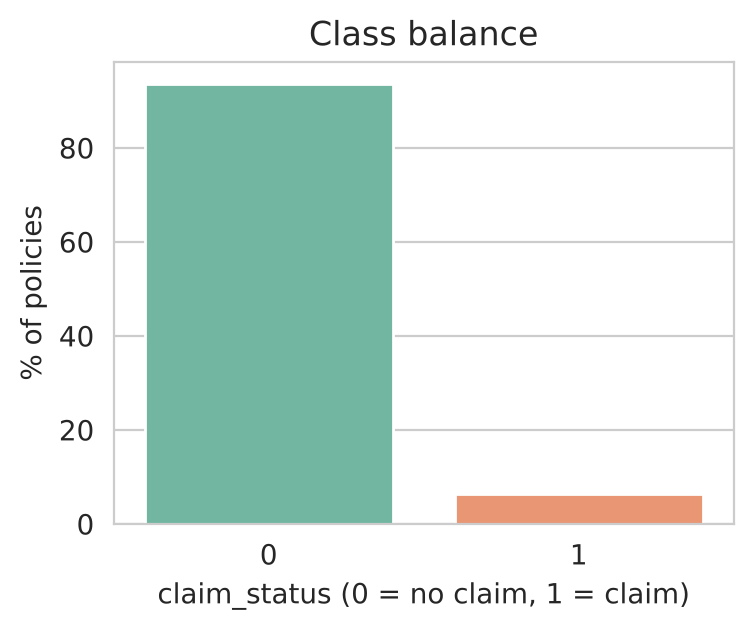

In [6]:
counts = df["claim_status"].value_counts()
percent = (df["claim_status"].value_counts(normalize=True) * 100).round(2)
print(counts, "\n")
print(percent)

plt.figure(figsize=(4, 3))
sns.barplot(x=percent.index.astype(str), y=percent.values, hue=percent.index.astype(str), palette="Set2", legend=False)
plt.xlabel("claim_status (0 = no claim, 1 = claim)")
plt.ylabel("% of policies")
plt.title("Class balance")
plt.show()

### ⚠️ The most important thing in this notebook: the data is **imbalanced**
About **93.6%** of policies have *no* claim and only about **6.4%** have a claim.

Imagine a lazy model that just says *"no claim"* for everyone. It would be right about 93.6% of the time, which sounds great, but it is **useless**, because it never finds a single person who will claim.

So for this project we do **not** judge models by *accuracy*. Instead we use:
- **ROC-AUC**: how well the model ranks risky policies above safe ones (0.5 = guessing, 1.0 = perfect).
- **Recall and precision of class 1**: of the people who really claim, how many do we catch, and how many of our "claim" warnings are right?

We also tell the models about the imbalance (using `class_weight="balanced"` and `scale_pos_weight`) so they don't just ignore the rare class.

## Part 4: Exploratory Data Analysis (EDA)
EDA means *looking at the data with tables and charts* to understand it and to decide which columns are worth keeping.

### Step 4.1: Sort the columns into numbers and text
- `select_dtypes(include="number")` picks the numeric columns (`num_col`).
- `select_dtypes(exclude="number")` picks everything else, which is text (`obj_col`).
- We remove `claim_status` (it is the target, not an input) and `policy_id` (just an ID label, which tells the model nothing useful).
- **Binary columns** are text columns that only contain "Yes" or "No". The line `set(df[c].unique()) <= {"Yes","No"}` means "the unique values are a subset of Yes/No".

In [7]:
num_col = df.select_dtypes(include="number").columns.to_list()
obj_col = df.select_dtypes(exclude="number").columns.to_list()

num_col.remove("claim_status")   # the target is not an input feature
obj_col.remove("policy_id")      # an ID has no predictive meaning

binary_col = [c for c in obj_col if set(df[c].unique()) <= {"Yes", "No"}]

print("Numeric columns :", len(num_col))
print("Text columns    :", len(obj_col))
print("Yes/No columns  :", len(binary_col))

Numeric columns : 12
Text columns    : 27
Yes/No columns  : 17


### Step 4.2: What values do the text columns contain?
For every text column we print how many different values it has (`nunique`) and a few examples. This tells us how to convert each one later:
- 2 values (Yes/No) → simple 1/0 conversion.
- A few values (like `model`, 11 of them) → one-hot encoding (explained in Part 7).
- Messy text (like `max_torque`) → needs extracting.

In [8]:
for col in obj_col:
    uniques = df[col].unique()
    print(f"{col:35s} - unique values: {df[col].nunique():3d} - sample: {uniques[:4]}")

region_code                         - unique values:  22 - sample: <ArrowStringArray>
['C8', 'C2', 'C10', 'C13']
Length: 4, dtype: str
segment                             - unique values:   6 - sample: <ArrowStringArray>
['C2', 'C1', 'A', 'B2']
Length: 4, dtype: str
model                               - unique values:  11 - sample: <ArrowStringArray>
['M4', 'M9', 'M1', 'M5']
Length: 4, dtype: str
fuel_type                           - unique values:   3 - sample: <ArrowStringArray>
['Diesel', 'CNG', 'Petrol']
Length: 3, dtype: str
max_torque                          - unique values:   9 - sample: <ArrowStringArray>
['250Nm@2750rpm', '200Nm@1750rpm', '60Nm@3500rpm', '200Nm@3000rpm']
Length: 4, dtype: str
max_power                           - unique values:   9 - sample: <ArrowStringArray>
['113.45bhp@4000rpm', '97.89bhp@3600rpm', '40.36bhp@6000rpm', '88.77bhp@4000rpm']
Length: 4, dtype: str
engine_type                         - unique values:  11 - sample: <ArrowStringArray>
['1.5 L U2 C

is_central_locking                  - unique values:   2 - sample: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
is_power_steering                   - unique values:   2 - sample: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
is_driver_seat_height_adjustable    - unique values:   2 - sample: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
is_day_night_rear_view_mirror       - unique values:   2 - sample: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
is_ecw                              - unique values:   2 - sample: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
is_speed_alert                      - unique values:   2 - sample: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


### Step 4.3: Numeric columns, do claimers look different?
`df[num_col].describe()` gives count, mean, spread (std), minimum, quartiles and maximum for every numeric column.

Then `groupby("claim_status")[num_col].mean()` compares the **average of each column** for people who did not claim (0) against people who did (1). A big difference between the two columns suggests a useful feature.

In [9]:
display(df[num_col].describe().T.round(2))
print("Average of each numeric column, split by claim_status:")
display(df.groupby("claim_status")[num_col].mean().T.round(2))

,count,mean,std,min,25%,50%,75%,max
subscription_length,58592.0,6.11,4.14,0.0,2.1,5.7,10.4,14.0
vehicle_age,58592.0,1.39,1.13,0.0,0.4,1.2,2.2,20.0
customer_age,58592.0,44.82,6.94,35.0,39.0,44.0,49.0,75.0
region_density,58592.0,18826.86,17660.17,290.0,6112.0,8794.0,27003.0,73430.0
airbags,58592.0,3.14,1.83,1.0,2.0,2.0,6.0,6.0
displacement,58592.0,1162.36,266.30,796.0,796.0,1197.0,1493.0,1498.0
cylinder,58592.0,3.63,0.48,3.0,3.0,4.0,4.0,4.0
turning_radius,58592.0,4.85,0.23,4.5,4.6,4.8,5.0,5.2
length,58592.0,3850.48,311.46,3445.0,3445.0,3845.0,3995.0,4300.0
width,58592.0,1672.23,112.09,1475.0,1515.0,1735.0,1755.0,1811.0


Average of each numeric column, split by claim_status:


claim_status,0,1
subscription_length,6.03,7.36
vehicle_age,1.40,1.27
customer_age,44.78,45.41
region_density,18909.07,17623.82
airbags,3.14,3.16
displacement,1161.82,1170.18
cylinder,3.63,3.65
turning_radius,4.85,4.86
length,3849.95,3858.21
width,1671.94,1676.50


**What to notice:** for most columns the 0 and 1 averages are almost the same. The clearest exception is **`subscription_length`**, which is higher for people who claimed (about 7.4 years versus 6.0). Customers who have been with the insurer longer claim a little more often. The car's size and weight columns barely differ.

### Step 4.4: Shapes and extreme values of the main numbers
- `describe(percentiles=[...])` adds extra cut points. The **1% and 99%** values show where the extreme ends are, so we can spot outliers (very strange values).
- A **histogram** shows how often each value range occurs. The smooth line (`kde=True`) is an outline of the same shape.

Look for: is it symmetric, or does it have a long tail to one side (**skewed**)? Are there spikes?

In [10]:
main_nums = ["subscription_length", "vehicle_age", "customer_age", "region_density"]

for col in main_nums:
    print(f"----- {col} -----")
    print(df[col].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2))
    print()

----- subscription_length -----
count    58592.00
mean         6.11
std          4.14
min          0.00
1%           0.10
5%           0.40
25%          2.10
50%          5.70
75%         10.40
95%         12.00
99%         12.40
max         14.00
Name: subscription_length, dtype: float64

----- vehicle_age -----
count    58592.00
mean         1.39
std          1.13
min          0.00
1%           0.00
5%           0.00
25%          0.40
50%          1.20
75%          2.20
95%          3.40
99%          4.20
max         20.00
Name: vehicle_age, dtype: float64

----- customer_age -----
count    58592.00
mean        44.82
std          6.94
min         35.00
1%          35.00
5%          35.00
25%         39.00
50%         44.00
75%         49.00
95%         58.00
99%         63.00
max         75.00
Name: customer_age, dtype: float64

----- region_density -----
count    58592.00
mean     18826.86
std      17660.17
min        290.00
1%         290.00
5%        4076.00
25%       6112.00
50% 

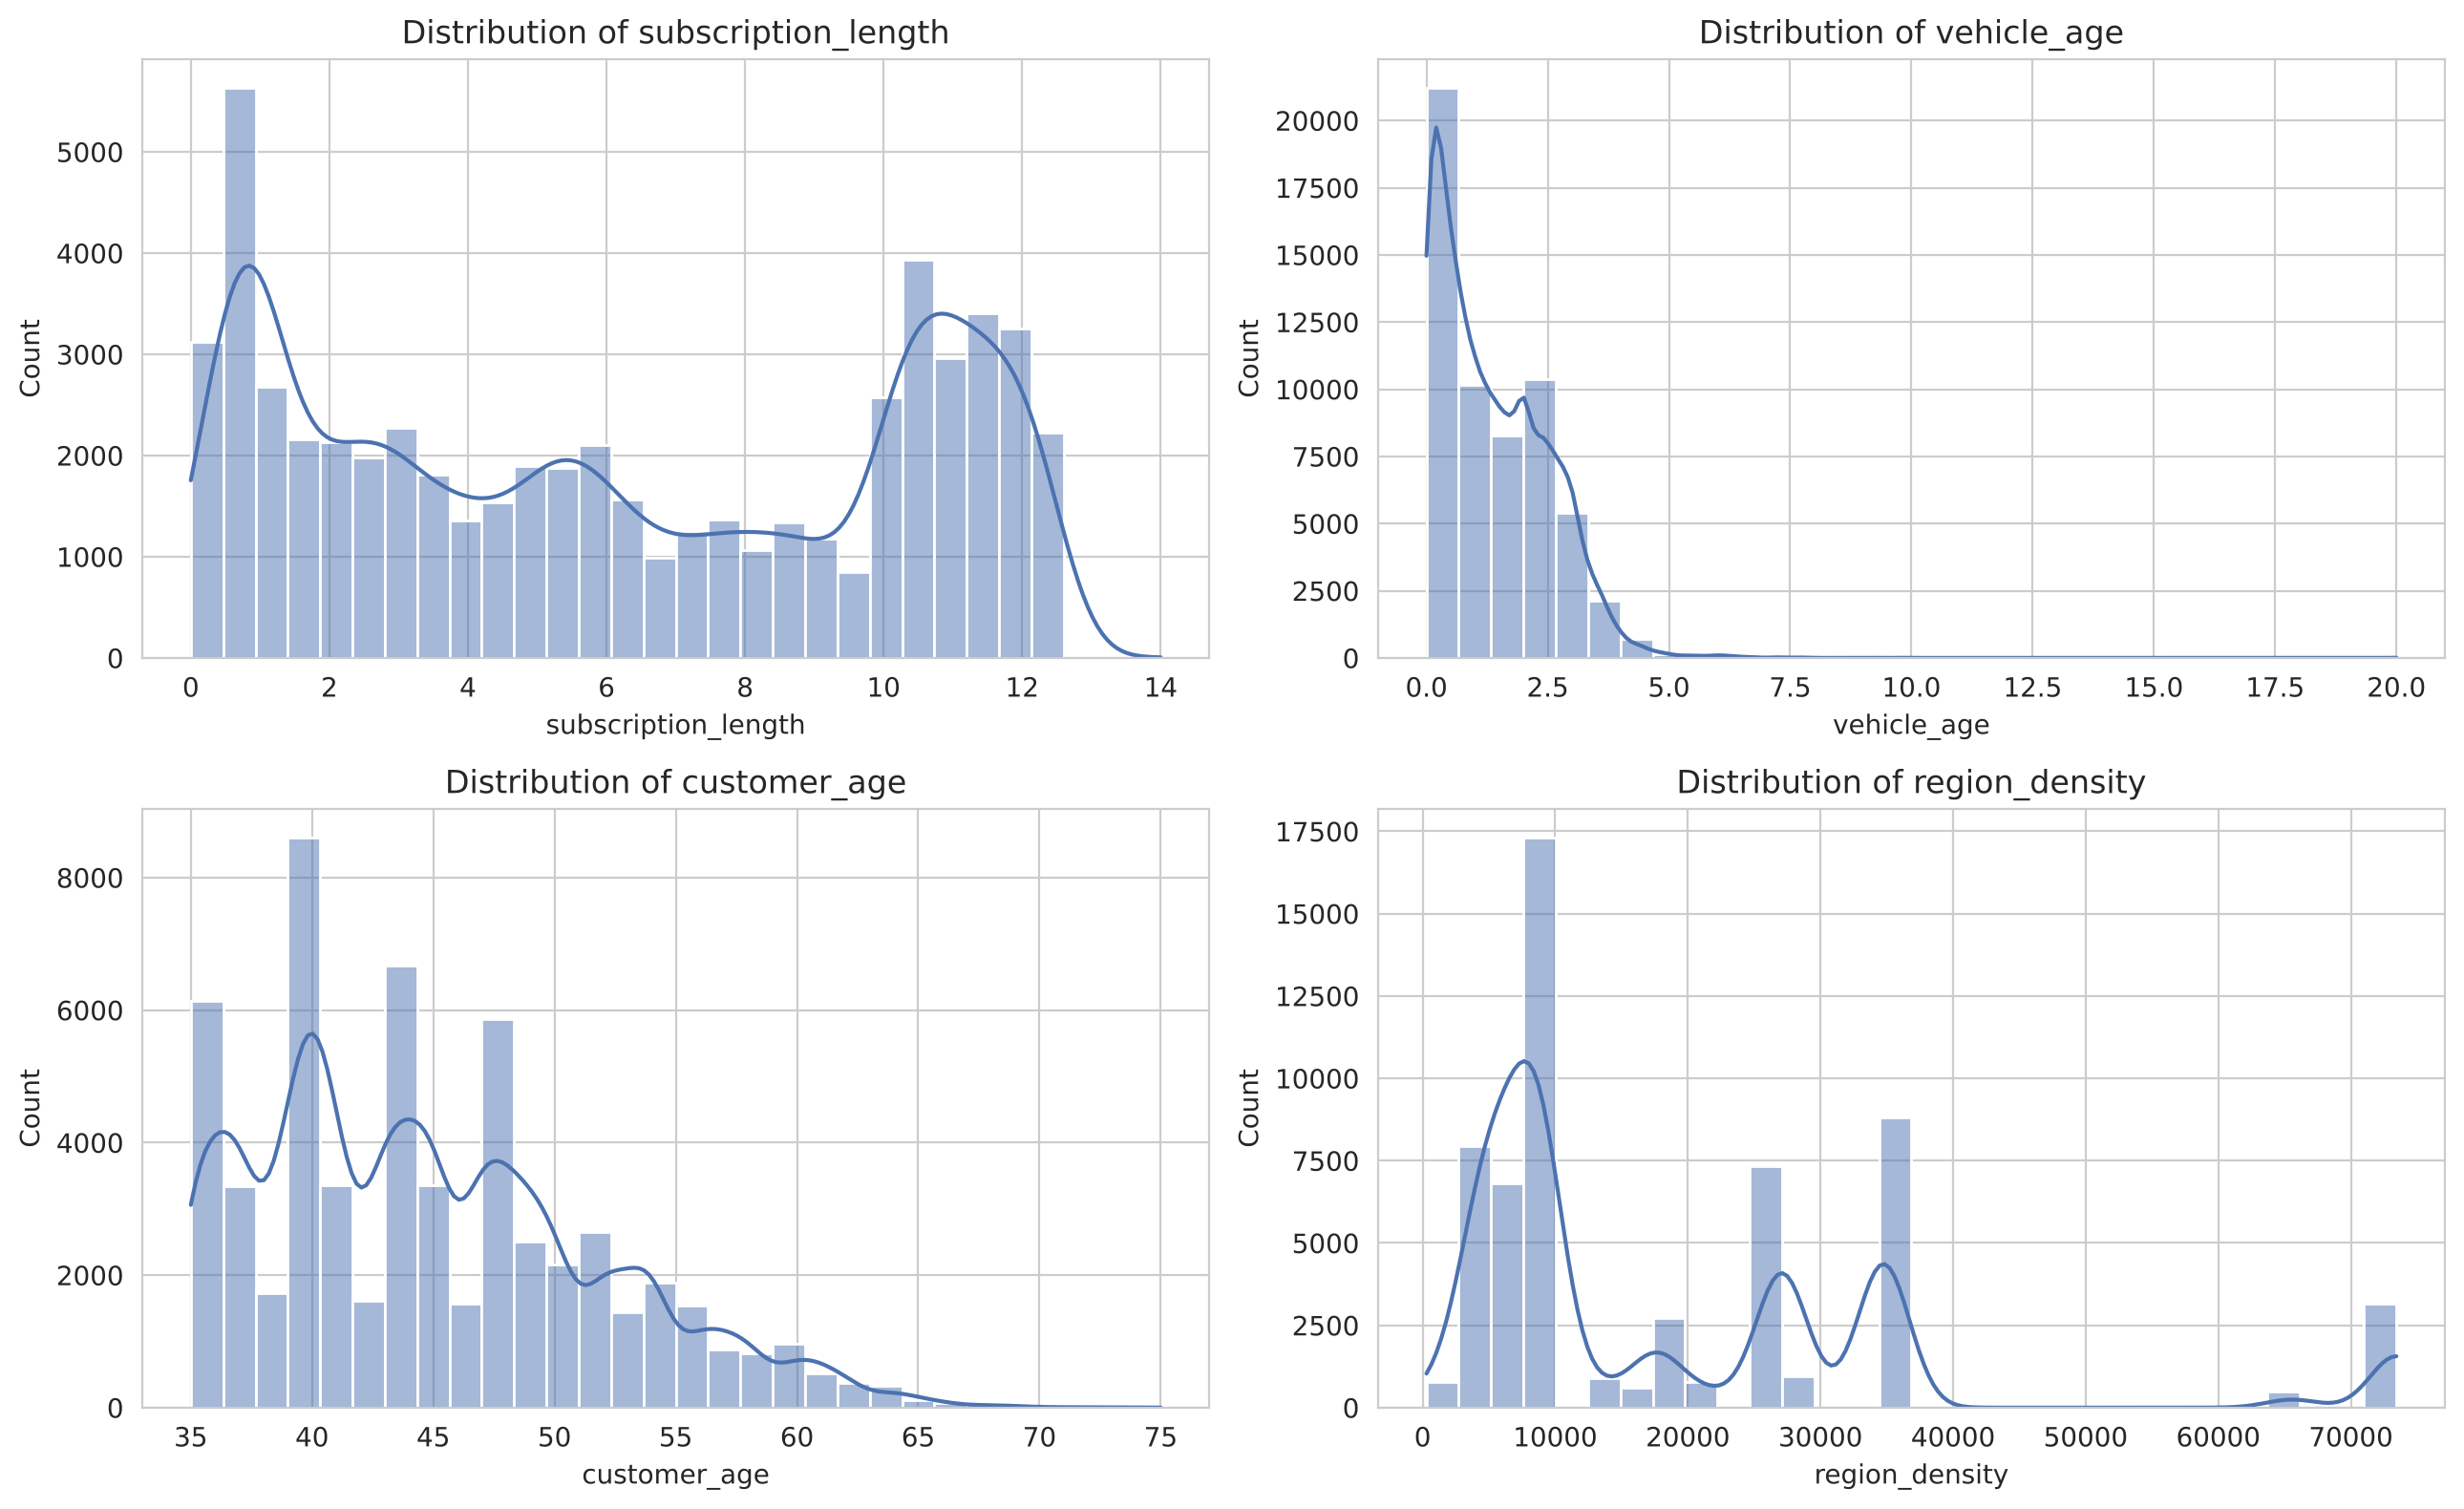

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, main_nums):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

**What to notice:** `vehicle_age` is strongly right-skewed (most cars are under 3 years old, a few are up to 20). `region_density` has a few distinct values with big spikes, because many policies come from the same regions. These are real values, not errors, so we keep them. Tree models (which we use) are not bothered by skewed numbers.

### Step 4.5: The Yes/No features, which ones separate claimers from non-claimers?
For each Yes/No column we calculate the **claim rate** (% of policies with a claim) separately for "Yes" and "No", and then the **gap** between them.

- `groupby(col)["claim_status"].mean()` gives the share of 1s in each group. Because `claim_status` is 0/1, its mean *is* the claim rate. Multiply by 100 for a percentage.
- A big gap means that knowing the feature tells us something about claims. A gap near 0 means the feature makes no difference.

(Remember: a gap shows a *relationship*, not that the feature *causes* claims.)

In [12]:
results = []
for col in binary_col:
    rates = df.groupby(col)["claim_status"].mean() * 100
    gap = abs(rates.get("Yes", 0) - rates.get("No", 0))
    results.append((col, rates.get("No", np.nan), rates.get("Yes", np.nan), gap))

gap_df = pd.DataFrame(results, columns=["feature", "claim_rate_No", "claim_rate_Yes", "gap"])
gap_df = gap_df.sort_values("gap", ascending=False)   # assign back, otherwise the sort is lost
display(gap_df.round(2))

,feature,claim_rate_No,claim_rate_Yes,gap
16,is_speed_alert,4.13,6.41,2.28
3,is_parking_sensors,5.39,6.44,1.05
1,is_adjustable_steering,5.97,6.67,0.70
5,is_front_fog_lights,6.06,6.64,0.59
9,is_brake_assist,6.10,6.64,0.54
13,is_driver_seat_height_adjustable,6.09,6.62,0.53
14,is_day_night_rear_view_mirror,6.24,6.65,0.40
12,is_power_steering,6.04,6.40,0.37
11,is_central_locking,6.13,6.50,0.36
15,is_ecw,6.13,6.50,0.36


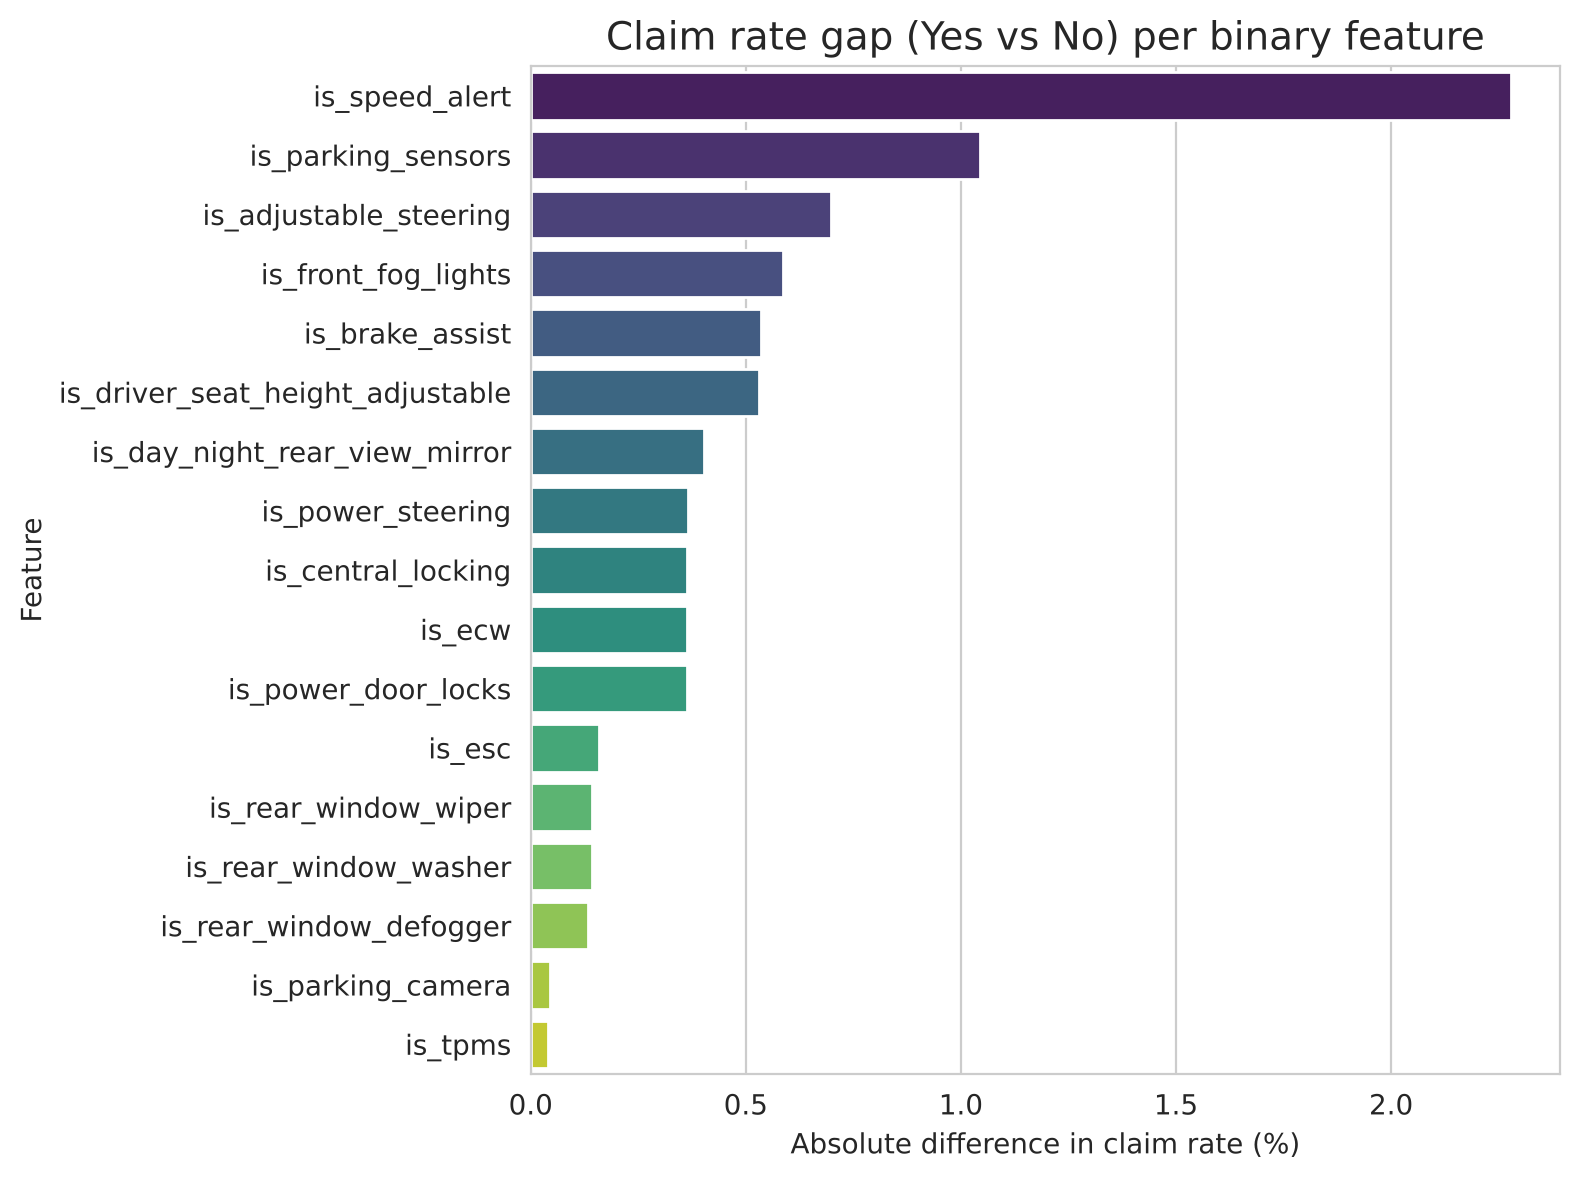

In [13]:
plt.figure(figsize=(8, 6))
sns.barplot(data=gap_df, y="feature", x="gap", hue="feature", palette="viridis", legend=False)
plt.title("Claim rate gap (Yes vs No) per binary feature", fontsize=14)
plt.xlabel("Absolute difference in claim rate (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**What to notice:** `is_speed_alert` has the biggest gap (about 2.3 percentage points). After it come `is_parking_sensors` (about 1.0) and `is_adjustable_steering` (about 0.7). Features such as `is_tpms` and `is_parking_camera` have almost no gap. **All the gaps are small**, which already warns us that predicting claims from these columns will be hard.

### Step 4.6: Text columns with several values (model, segment, fuel type, ...)
For each of these columns we show the **count** (how many policies) and the **claim rate** per value, sorted by count.

⚠️ Always read the **count** next to the rate. A group with only 20 policies and 3 claims shows 15%, but with so little data it is just noise.

In [14]:
cat_to_explore = ["region_code", "model", "segment", "fuel_type", "transmission_type", "steering_type"]

for col in cat_to_explore:
    grp = df.groupby(col)["claim_status"].agg(["count", "mean"]).sort_values("count", ascending=False)
    grp["mean"] = (grp["mean"] * 100).round(2)
    grp = grp.rename(columns={"mean": "claim_rate_%"})
    print(f"------ {col} ({df[col].nunique()} values) ------")
    print(grp.head(10))
    print()

------ region_code (22 values) ------
             count  claim_rate_%
region_code                     
C8           13654          6.99
C2            7342          7.08
C5            6979          5.77
C3            6101          7.10
C14           3660          7.68
C13           3423          5.70
C10           3155          4.69
C9            2734          4.97
C7            2167          5.03
C12           1589          5.48

------ model (11 values) ------
       count  claim_rate_%
model                     
M1     14948          6.14
M4     14018          6.43
M6     13776          6.82
M8      4173          5.85
M7      2940          6.84
M3      2373          5.39
M9      2114          6.29
M5      1598          7.26
M10     1209          6.04
M2      1080          7.41

------ segment (6 values) ------
         count  claim_rate_%
segment                     
B2       18314          6.86
A        17321          6.04
C2       14018          6.43
B1        4173          5.85
C

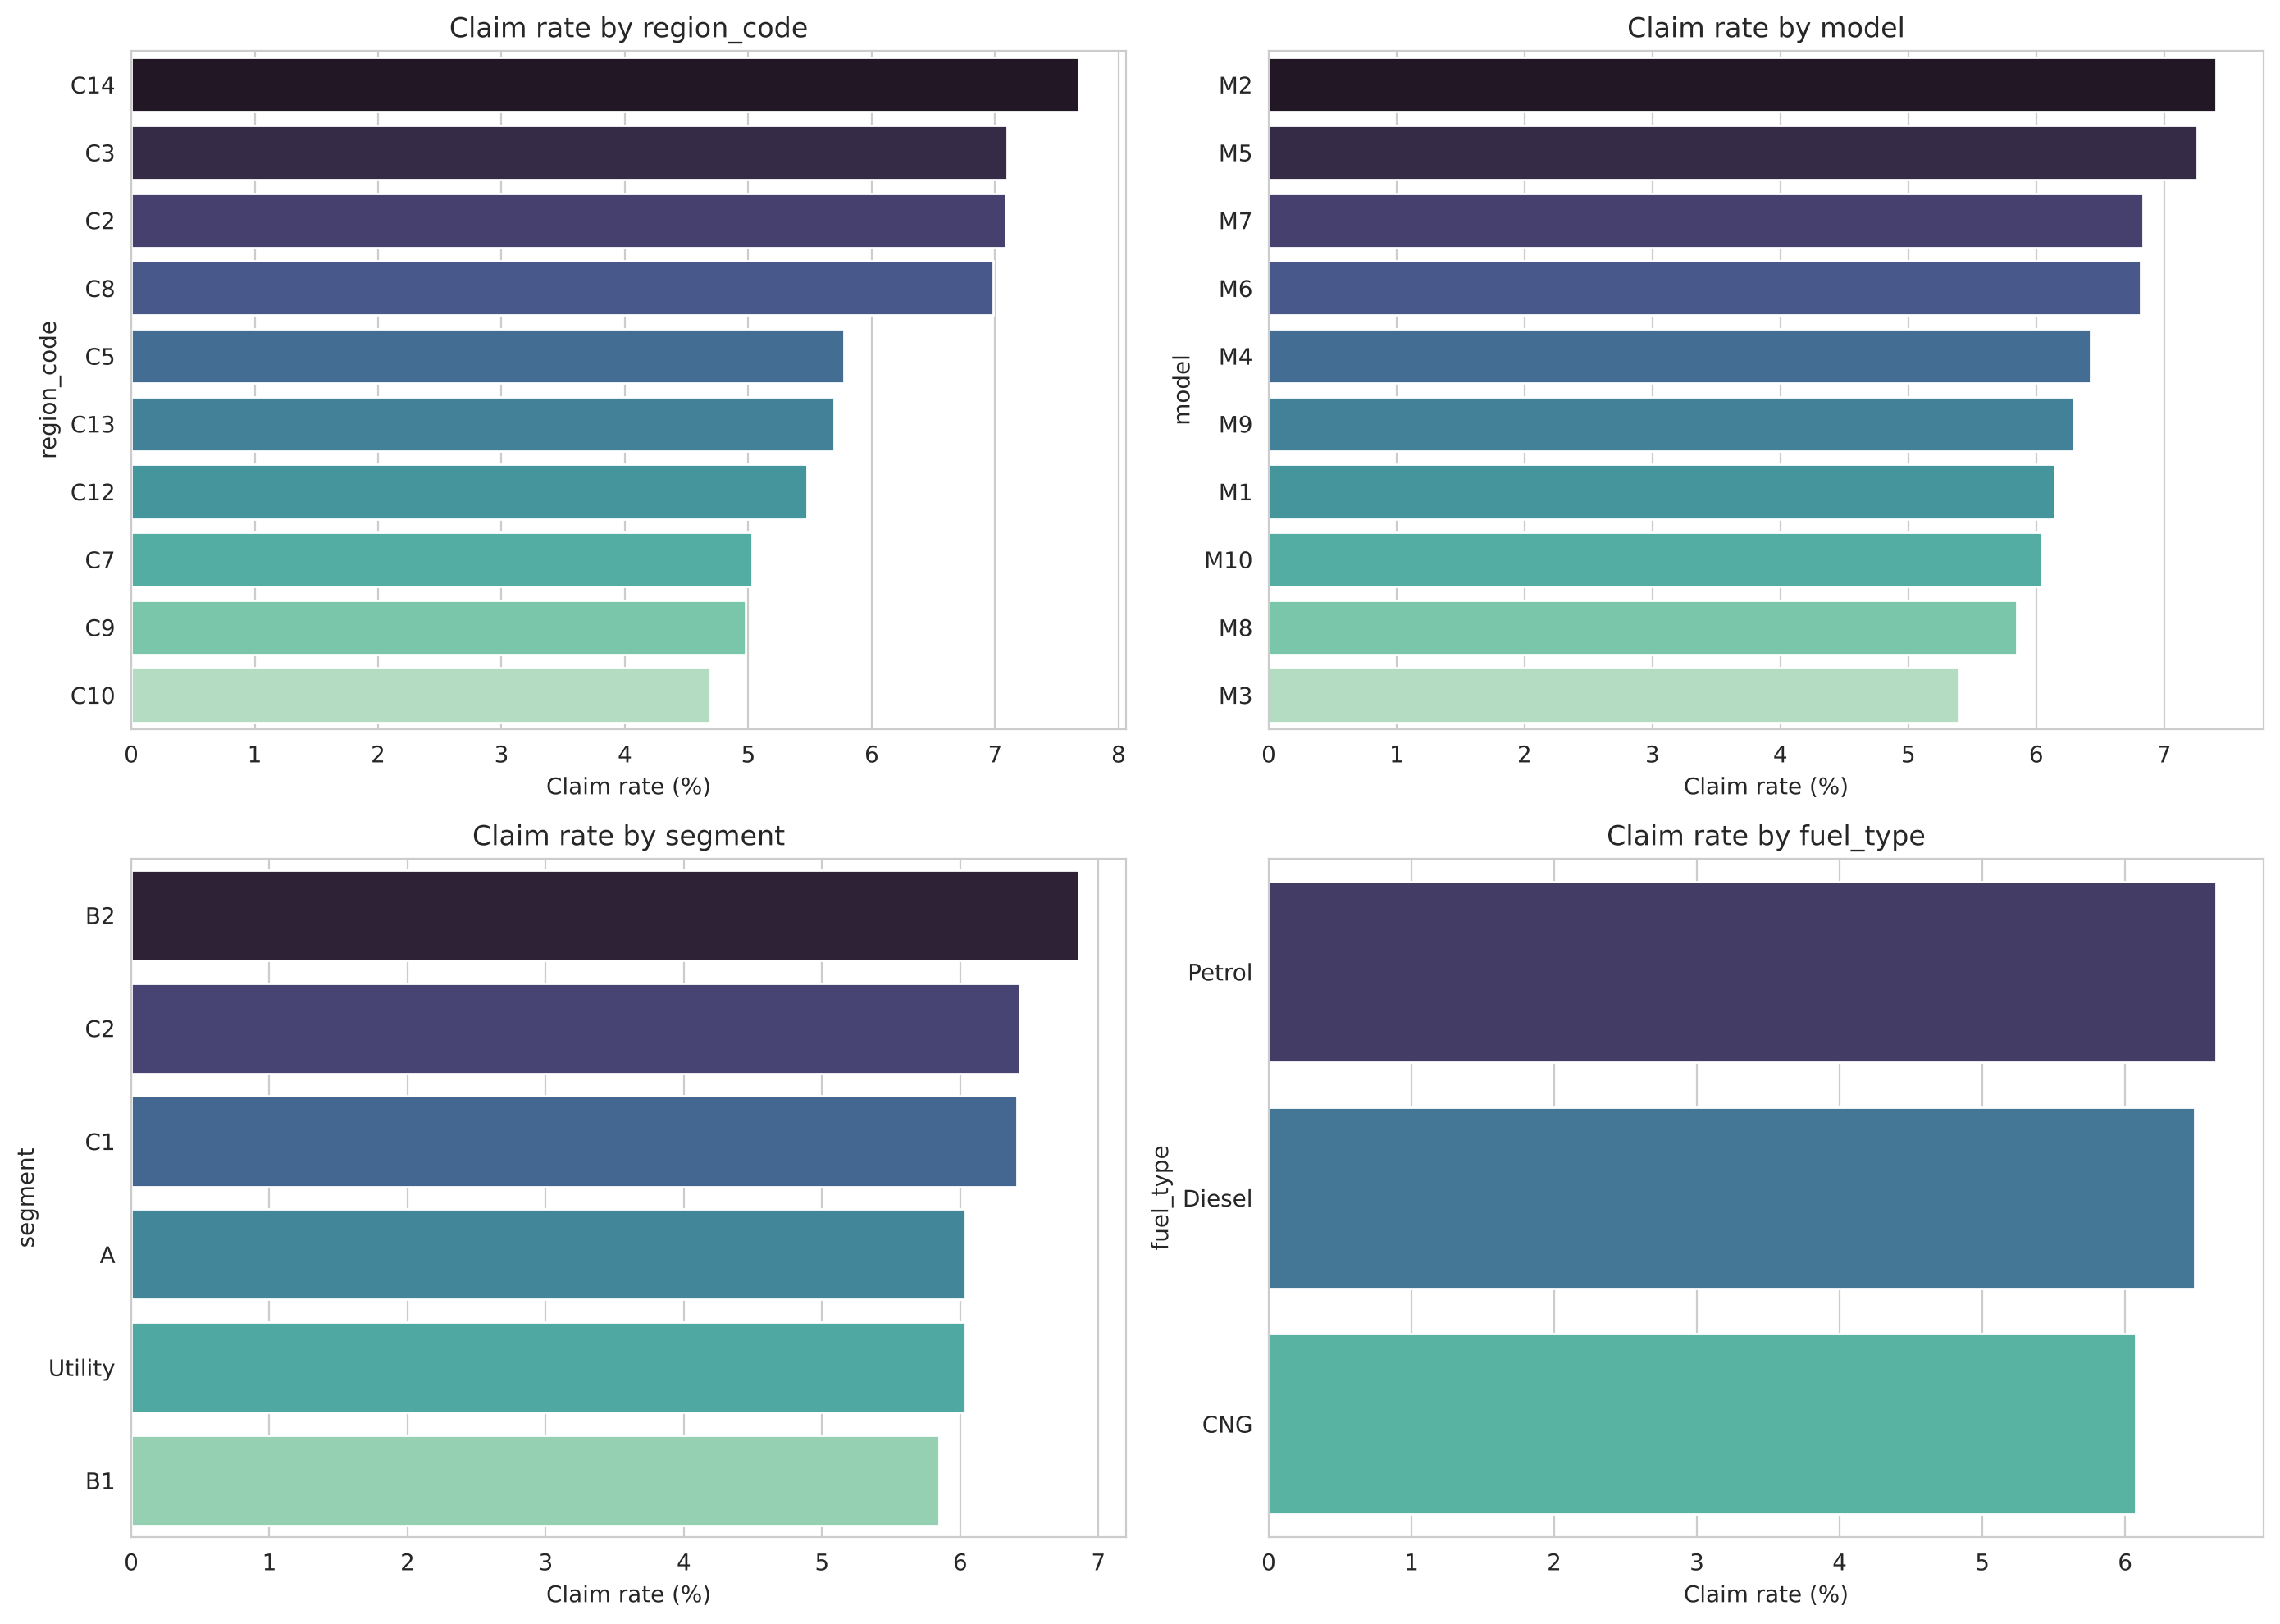

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, ["region_code", "model", "segment", "fuel_type"]):
    top = df[col].value_counts().head(10).index            # only the 10 biggest groups
    grp = (df[df[col].isin(top)].groupby(col)["claim_status"].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=grp.values, y=grp.index, hue=grp.index, ax=ax, palette="mako", legend=False)
    ax.set_title(f"Claim rate by {col}")
    ax.set_xlabel("Claim rate (%)")

plt.tight_layout()
plt.show()

**What to notice:** claim rates are all fairly close to the 6.4% average (roughly 5.4% to 7.7%). Some regions and models are slightly higher or lower, but no single group stands out strongly.

### Step 4.7: Correlation heatmap
**Correlation** measures how strongly two numeric columns move together, from -1 to +1.
- +1: when one goes up, the other always goes up.
- 0: no straight-line relationship.
- -1: when one goes up, the other goes down.

The heatmap colours each pair (red = positive, blue = negative). **Look at the `claim_status` row/column first**, which shows what is related to claims. Also look for pairs of input columns with a high correlation (like `length`, `width` and `gross_weight`): they carry nearly the same information.

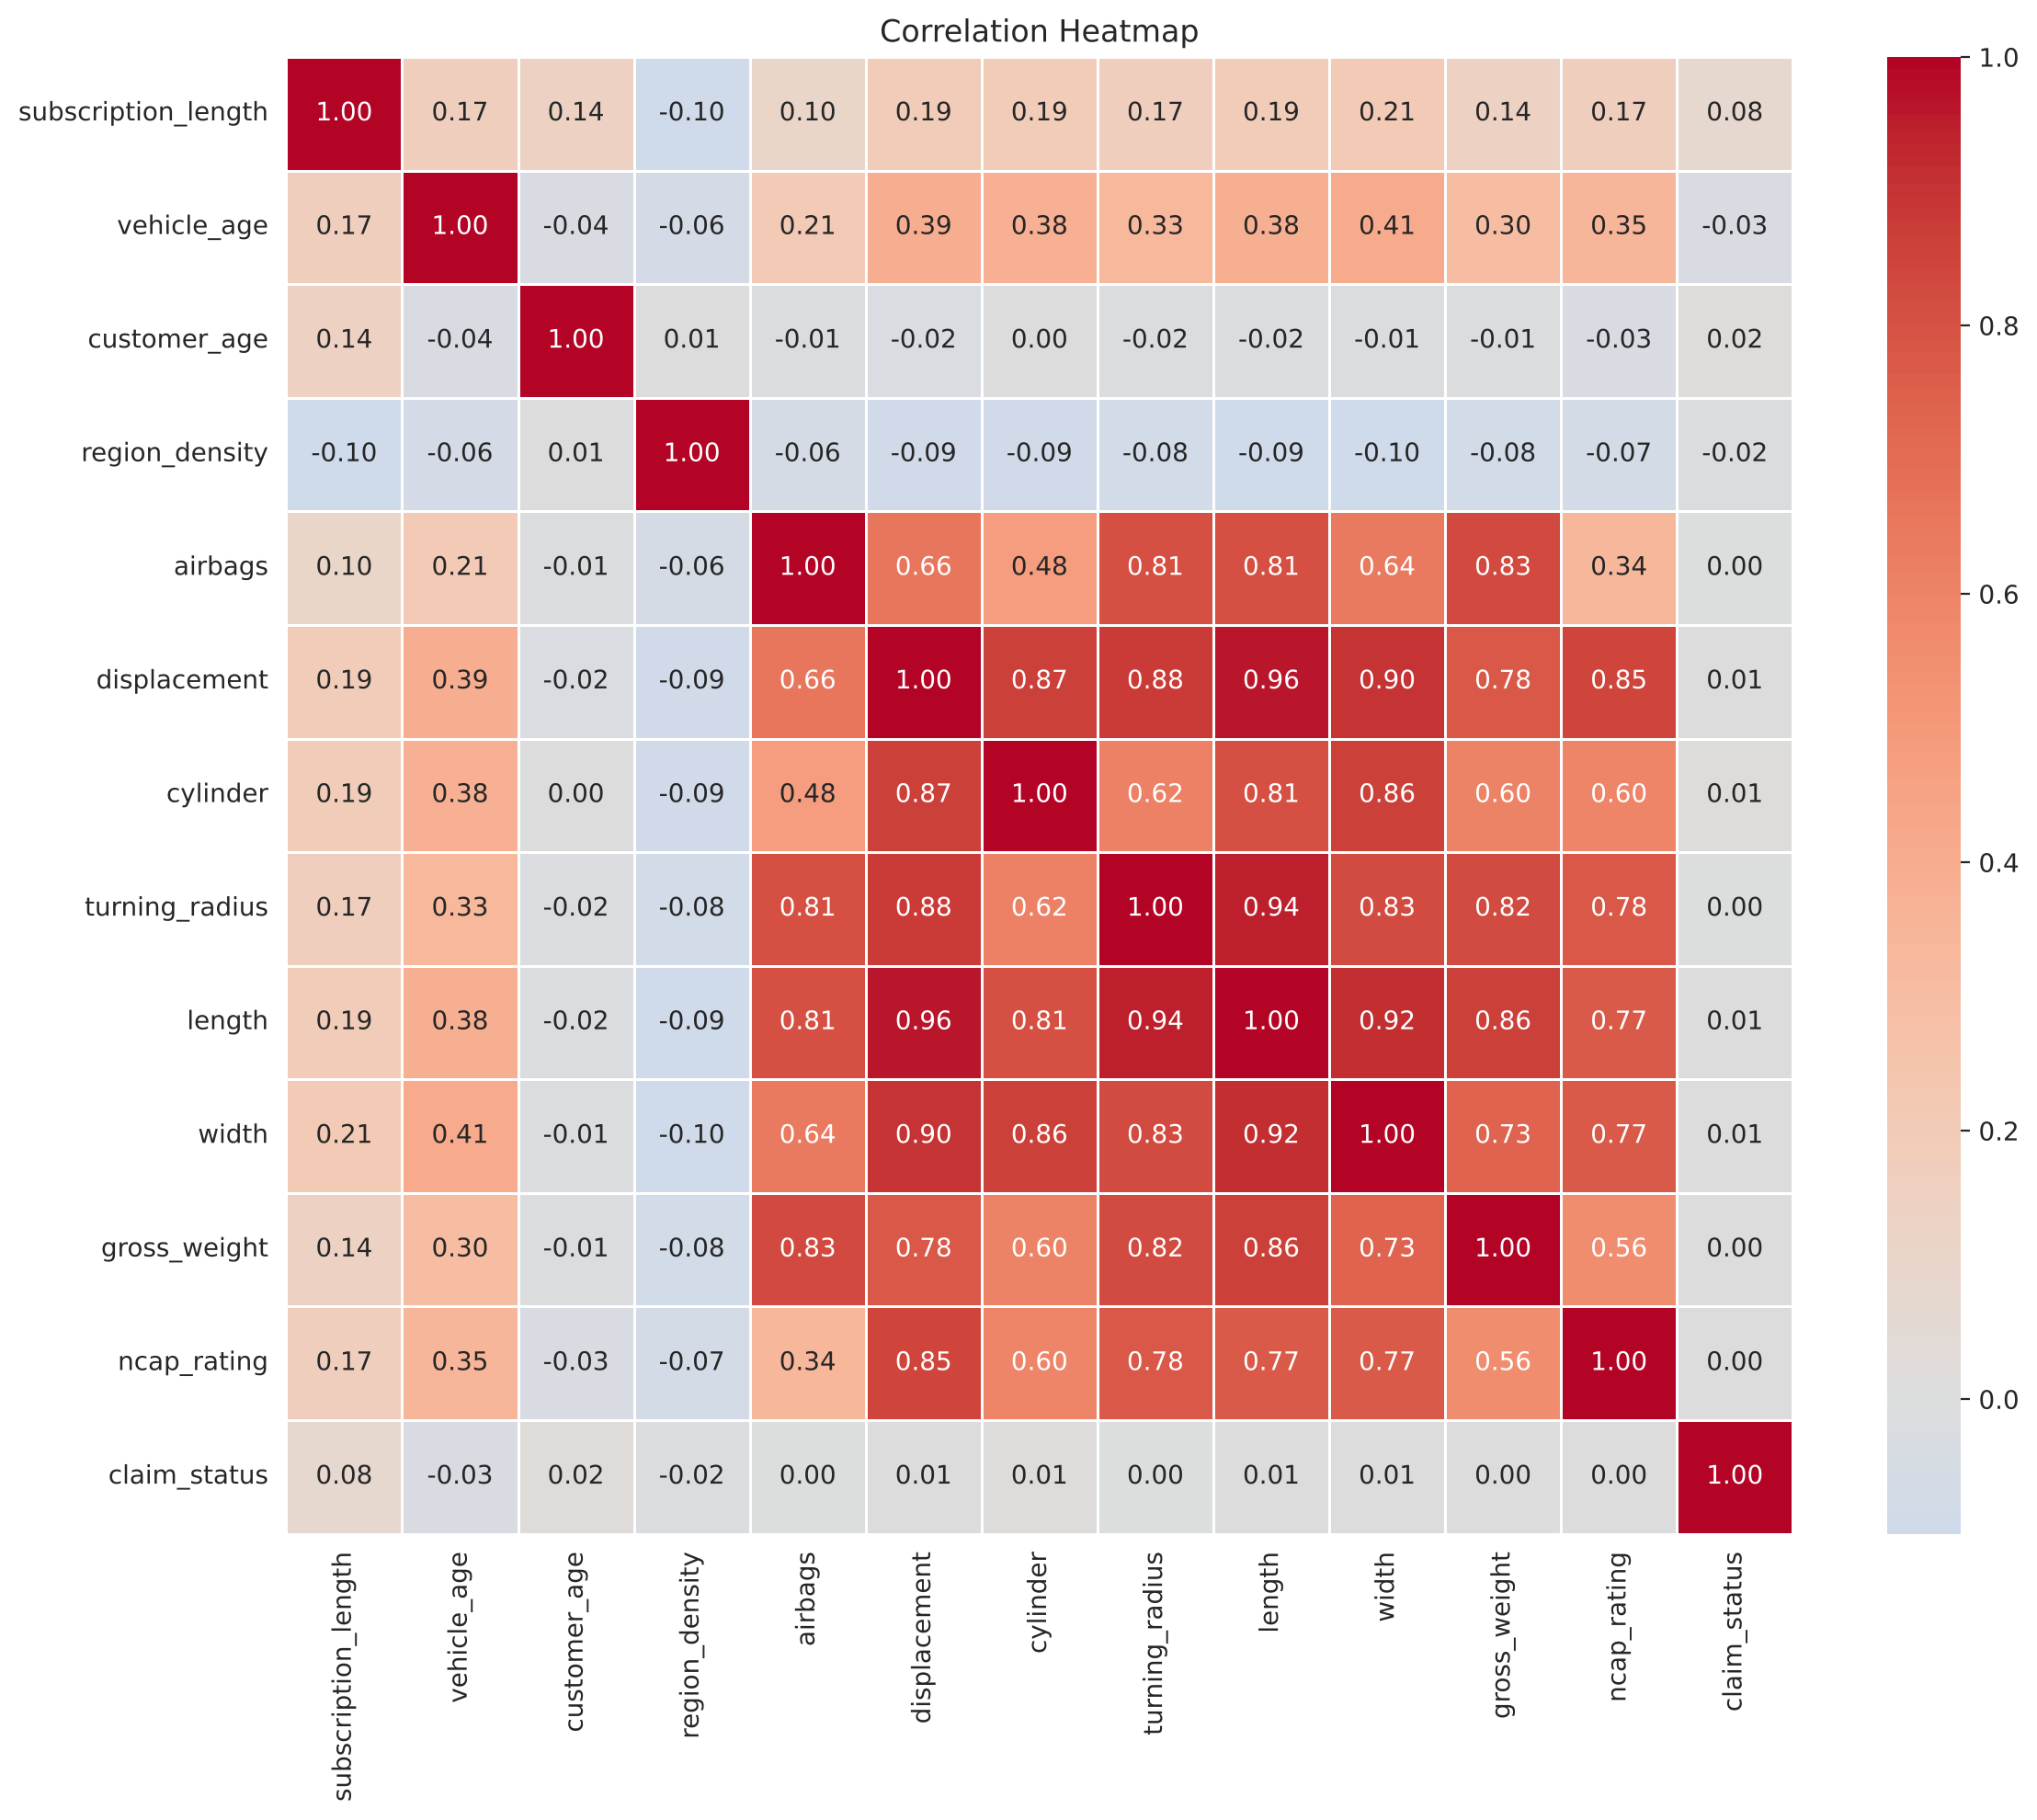

Correlation with claim_status (strongest first):
subscription_length    0.079
vehicle_age           -0.028
customer_age           0.022
region_density        -0.018
cylinder               0.013
width                  0.010
displacement           0.008
length                 0.006
gross_weight           0.004
ncap_rating            0.004
airbags                0.003
turning_radius         0.003
Name: claim_status, dtype: float64


In [16]:
corr = df[num_col + ["claim_status"]].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlation with claim_status (strongest first):")
print(corr["claim_status"].drop("claim_status").sort_values(key=abs, ascending=False).round(3))

**What to notice:** `claim_status` has very weak correlations with everything. The largest is `subscription_length` at about 0.08. This tells us honestly that claims are hard to predict from this data, so our final model will only be modestly better than guessing, which is common in insurance problems.

### Step 4.8: A key discovery: every car feature is decided by the `model` column
There are only **11 car models**. Is it possible that all the car specification columns (engine, size, safety features) are fixed for each model? We test this: for every spec column, we count how many different values it has **within one model**. If the answer is always 1, the column is completely decided by the model.

In [17]:
spec_cols = [c for c in df.columns if c not in
             ["policy_id", "subscription_length", "vehicle_age", "customer_age",
              "region_code", "region_density", "model", "claim_status"]]

max_values_per_model = {c: int(df.groupby("model")[c].nunique().max()) for c in spec_cols}
print("Columns where the value changes within the same model:",
      [c for c, v in max_values_per_model.items() if v > 1])
print("Number of spec columns fully decided by 'model':", sum(v == 1 for v in max_values_per_model.values()), "of", len(spec_cols))

Columns where the value changes within the same model: []
Number of spec columns fully decided by 'model': 33 of 33


**Meaning:** all the car specification columns are fixed once you know the `model`. So `fuel_type`, `airbags`, `is_esc`, `is_speed_alert` and the others are really **just different labels for the same 11 cars**. They do not add new information beyond `model`.

This is why we can drop most of them in Part 6 without losing much, and why a Yes/No feature like `is_speed_alert` showing a "gap" is partly just reflecting *which car models have it*.

## Part 5: Feature extraction, turning text into numbers
`max_torque` and `max_power` hold text such as `250Nm@2750rpm` and `113.45bhp@4000rpm`. A model can't read that, but the numbers inside (the torque, the power, and the rpm at which they happen) are useful, so we extract them.

### The tool: regular expressions (regex)
A regex is a pattern for finding text. Here:
- `([\d.]+)` means "capture one or more digits or dots" (a number like `113.45`). The brackets mean *capture this part*.
- `Nm@` and `rpm` are literal text that must be present, just before and after the numbers.
- `.str.extract(pattern)` applies the pattern to every row and returns one column per bracket pair.
- `.astype(float)` turns the captured text into real numbers.

Rows that don't match the pattern become `NaN`, so we check for that afterwards.

In [18]:
torque_parsed = df["max_torque"].str.extract(r"([\d.]+)Nm@([\d.]+)rpm").astype(float)
power_parsed  = df["max_power"].str.extract(r"([\d.]+)bhp@([\d.]+)rpm").astype(float)

df["torque_Nm"]  = torque_parsed[0]
df["torque_rpm"] = torque_parsed[1]
df["power_bhp"]  = power_parsed[0]
df["power_rpm"]  = power_parsed[1]

new_cols = ["torque_Nm", "torque_rpm", "power_bhp", "power_rpm"]
print("Missing values after extraction:\n", df[new_cols].isna().sum())
display(df[["max_torque", "max_power"] + new_cols].head(3))

Missing values after extraction:
 torque_Nm     0
torque_rpm    0
power_bhp     0
power_rpm     0
dtype: int64


,max_torque,max_power,torque_Nm,torque_rpm,power_bhp,power_rpm
0,250Nm@2750rpm,113.45bhp@4000rpm,250.0,2750.0,113.45,4000.0
1,200Nm@1750rpm,97.89bhp@3600rpm,200.0,1750.0,97.89,3600.0
2,250Nm@2750rpm,113.45bhp@4000rpm,250.0,2750.0,113.45,4000.0


### Do the new columns help?
We check their correlation with `claim_status`. If it is near 0, they add little, and since they are also decided by `model` (Step 4.8), we can leave them out of the final model.

In [19]:
print(df[new_cols + ["claim_status"]].corr()["claim_status"].drop("claim_status").round(3))

torque_Nm     0.004
torque_rpm    0.005
power_bhp     0.008
power_rpm     0.000
Name: claim_status, dtype: float64


The correlations are tiny, so we do not use these four columns in the final model. Extraction is still a useful skill, since in other projects the parsed numbers may matter a lot.

## Part 6: Feature selection, choose the columns for the model

**Why not use all the columns?** More columns are not always better. Columns that repeat the same information or add only noise can make the model slower and sometimes worse.

### What we keep
| Group | Columns | Why |
|---|---|---|
| Numeric | `subscription_length`, `vehicle_age`, `customer_age`, `region_density` | The real customer/policy details |
| Car model | `model` | Stands for all the car specs (Step 4.8) |
| Yes/No | the 7 features with the largest gap in Step 4.5 that you chose: `is_parking_sensors`, `is_front_fog_lights`, `is_brake_assist`, `is_power_steering`, `is_driver_seat_height_adjustable`, `is_day_night_rear_view_mirror`, `is_speed_alert` | Safety/comfort features that showed some difference |
| Target | `claim_status` | What we predict |

### What we drop
- **`policy_id`**: just a label.
- **Car spec columns** (engine, size, weight, `segment`, `fuel_type`, `ncap_rating`, ...): fully decided by `model`.
- **Yes/No features with a tiny gap** (`is_tpms`, `is_parking_camera`, `is_esc`, ...): they barely change the claim rate.
- **`region_code`**: 22 values, which would create many extra columns for a small gain. `region_density` already describes the region numerically.
- **The extracted torque/power columns**: weak, and decided by `model`.

*Note:* `is_adjustable_steering` had the third-largest gap but is not in your list. If that was a deliberate choice (it overlaps with the other steering columns), that's fine. You can try adding it to `binary_final` and re-running to see whether it improves the scores.

In [20]:
numeric_final     = ["subscription_length", "vehicle_age", "customer_age", "region_density"]
categorical_final = ["model"]
binary_final      = ["is_parking_sensors", "is_front_fog_lights", "is_brake_assist",
                     "is_power_steering", "is_driver_seat_height_adjustable",
                     "is_day_night_rear_view_mirror", "is_speed_alert"]
target            = "claim_status"

# .copy() makes an independent table, so changes below do not touch the original df
df_clean = df[numeric_final + categorical_final + binary_final + [target]].copy()

dropped = [c for c in df.columns if c not in df_clean.columns]
print("Columns kept   :", df_clean.shape[1])
print("Columns dropped:", len(dropped))
print(dropped)

Columns kept   : 13
Columns dropped: 32
['policy_id', 'region_code', 'segment', 'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder', 'transmission_type', 'steering_type', 'turning_radius', 'length', 'width', 'gross_weight', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_power_door_locks', 'is_central_locking', 'is_ecw', 'ncap_rating', 'torque_Nm', 'torque_rpm', 'power_bhp', 'power_rpm']


## Part 7: Encoding, turning text into numbers

Machine learning models only understand numbers, so the remaining text columns must be converted.

### Step 7.1: Yes/No → 1/0
`.map({"yes": 1, "no": 0})` replaces each value using the dictionary.

⚠️ **Common trap:** `.map()` turns any value that is *not* in the dictionary into `NaN`. If you run this cell a second time, the column already holds 1/0, none of which match "Yes"/"No", so everything becomes `NaN`. To make the cell **safe to re-run**, the code below first converts to lowercase text and accepts both yes/no and 1/0.

In [21]:
yes_no_map = {"yes": 1, "no": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0}

for col in binary_final:
    df_clean[col] = df_clean[col].astype(str).str.strip().str.lower().map(yes_no_map)

print("Missing values after mapping (must all be 0):")
print(df_clean[binary_final].isna().sum().sum())
display(df_clean[binary_final].head(3))

Missing values after mapping (must all be 0):
0


,is_parking_sensors,is_front_fog_lights,is_brake_assist,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_speed_alert
0,1,1,1,1,1,0,1
1,1,1,0,1,1,1,1
2,1,1,1,1,1,0,1


### Step 7.2: Save the list of car models (for the web app later)
The app needs the list of car models for its drop-down menu. We store it **now**, before the `model` column disappears in the next step.

In [22]:
model_options = sorted(df_clean["model"].unique().tolist())
print(model_options)

['M1', 'M10', 'M11', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']


### Step 7.3: One-hot encoding for `model`
The car model has 11 names (`M1` ... `M11`) with **no natural order**. If we simply numbered them 1 to 11, the model would wrongly think M11 is "bigger" than M2.

**One-hot encoding** creates one new 0/1 column per model: `model_M1`, `model_M2`, ... Each row has a **1 in the column for its own model** and 0 in the others.

| model | → | model_M1 | model_M4 | model_M9 |
|---|---|---|---|---|
| M4 | | 0 | 1 | 0 |
| M9 | | 0 | 0 | 1 |

`pd.get_dummies(..., dtype=int)` does this. Without `dtype=int` you get `True/False` instead of 1/0.

In [23]:
df_model = pd.get_dummies(df_clean, columns=["model"], dtype=int)

print("Shape after encoding:", df_model.shape)
print(list(df_model.columns))
df_model.head(3)

Shape after encoding: (58592, 23)
['subscription_length', 'vehicle_age', 'customer_age', 'region_density', 'is_parking_sensors', 'is_front_fog_lights', 'is_brake_assist', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_speed_alert', 'claim_status', 'model_M1', 'model_M10', 'model_M11', 'model_M2', 'model_M3', 'model_M4', 'model_M5', 'model_M6', 'model_M7', 'model_M8', 'model_M9']


,subscription_length,vehicle_age,customer_age,region_density,is_parking_sensors,is_front_fog_lights,is_brake_assist,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_speed_alert,claim_status,model_M1,model_M10,model_M11,model_M2,model_M3,model_M4,model_M5,model_M6,model_M7,model_M8,model_M9
0,9.3,1.2,41,8794,1,1,1,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0
1,8.2,1.8,35,27003,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1
2,9.5,0.2,44,8794,1,1,1,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0


## Part 8: Train/test split

### Step 8.1: Inputs (X) and answer (y)
- **`X`**: all the columns the model learns from (features).
- **`y`**: the column we want to predict (the target).

### Step 8.2: Why split the data?
If we tested the model on the same rows it learned from, it could just memorize them and look perfect, but it would fail on new customers. So we split:
- **Train set (80%)**: the model learns from this.
- **Test set (20%)**: kept hidden until the end, to give an honest score on *new* data.

`stratify=y` is important for imbalanced data. It makes sure that the train and test sets both keep the same 6.4% claim rate. Without it, the small test set could end up with very few claims by chance.

In [24]:
X = df_model.drop(columns=[target])
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| claim rate:", round(y_train.mean() * 100, 2), "%")
print("Test :", X_test.shape,  "| claim rate:", round(y_test.mean() * 100, 2), "%")

Train: (46873, 22) | claim rate: 6.4 %
Test : (11719, 22) | claim rate: 6.4 %


No scaling step is needed here: Decision Trees, Random Forests and XGBoost split data by thresholds, so the size of the numbers doesn't matter. (Neural networks, like in your insurance charges assignment, **do** need scaling.)

## Part 9: Train the models

We compare three models, from simple to powerful.

| Model | Idea in plain words |
|---|---|
| **Decision Tree** | A flowchart of yes/no questions ("is subscription length > 8?") that ends in a prediction. Easy to understand, but can overfit. |
| **Random Forest** | Hundreds of different decision trees that vote. More stable than one tree. |
| **XGBoost** | Trees built one after another, each fixing the mistakes of the last. Often the strongest on tables. |

### Handling the imbalance
Without help, the models would focus on the 93.6% "no claim" cases and ignore the claims.
- `class_weight="balanced"` (tree and forest) makes each claim count more during training.
- `scale_pos_weight` (XGBoost) does the same: the ratio of no-claims to claims (about 14.6).

### Settings that limit overfitting
`max_depth` limits how many questions a tree may ask, and `min_samples_leaf` stops the tree from making a rule for just a handful of policies. Without these limits a tree can memorize the training data. These values are reasonable starting points and can be tuned.

`model.fit(X_train, y_train)` is the line where the learning happens.

In [25]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(scale_pos_weight, 2))

dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=100,
                            class_weight="balanced", random_state=RANDOM_STATE)

rf = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=50,
                            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=scale_pos_weight, eval_metric="auc",
                    random_state=RANDOM_STATE)

models = [("Decision Tree", dt), ("Random Forest", rf), ("XGBoost", xgb)]

for name, model in models:
    model.fit(X_train, y_train)
    print(name, "trained")

scale_pos_weight: 14.63
Decision Tree trained


Random Forest trained


XGBoost trained


## Part 10: Evaluate the models

### The scores you will see
After a model predicts, we compare its predictions with the truth on the **test set**.

- **Precision (class 1):** of the policies the model *flagged as claims*, what share really claimed? (Low precision = many false alarms.)
- **Recall (class 1):** of the policies that *really claimed*, what share did the model catch? (Low recall = missed claims.)
- **F1-score:** a single number combining precision and recall.
- **ROC-AUC:** how well the predicted *probabilities* rank claimers above non-claimers. 0.5 = no better than a coin flip, 1.0 = perfect. This is our main comparison number, because it does not depend on a threshold.

### Two kinds of output from a model
- `predict_proba(X)[:, 1]` gives the **probability** of a claim (for example 0.37). The `[:, 1]` selects the column for class 1.
- `predict(X)` gives a **yes/no** answer by applying a threshold (0.5 by default): probability ≥ 0.5 → "claim".

⚠️ Accuracy is not shown as a headline number for the reason in Part 3.

In [26]:
auc_scores = {}

for name, model in models:
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probs)
    auc_scores[name] = auc

    print(f"----- {name} -----")
    print(classification_report(y_test, preds, digits=3))
    print("ROC-AUC:", round(auc, 4))
    print()

----- Decision Tree -----
              precision    recall  f1-score   support

           0      0.966     0.483     0.644     10969
           1      0.091     0.755     0.162       750

    accuracy                          0.501     11719
   macro avg      0.529     0.619     0.403     11719
weighted avg      0.910     0.501     0.614     11719

ROC-AUC: 0.648



----- Random Forest -----
              precision    recall  f1-score   support

           0      0.965     0.543     0.695     10969
           1      0.096     0.711     0.169       750

    accuracy                          0.554     11719
   macro avg      0.530     0.627     0.432     11719
weighted avg      0.909     0.554     0.661     11719

ROC-AUC: 0.6623

----- XGBoost -----
              precision    recall  f1-score   support

           0      0.960     0.586     0.728     10969
           1      0.096     0.647     0.168       750

    accuracy                          0.590     11719
   macro avg      0.528     0.616     0.448     11719
weighted avg      0.905     0.590     0.692     11719

ROC-AUC: 0.6583



### Step 10.2: Compare the models and choose the best
`max(auc_scores, key=auc_scores.get)` finds the model name with the **highest AUC**. (The `key=` part makes `max` compare the scores instead of the alphabetical names.) `dict(models)[best_name]` then fetches that fitted model object.

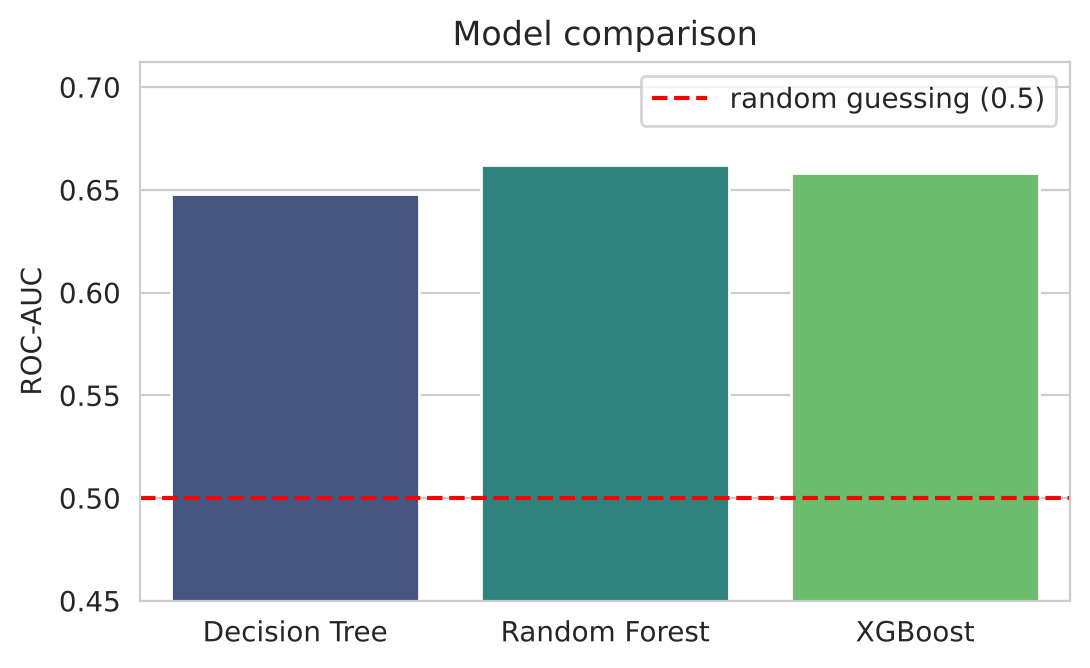

Best model: Random Forest | AUC = 0.6623


In [27]:
best_name = max(auc_scores, key=auc_scores.get)
best_model = dict(models)[best_name]

plt.figure(figsize=(6, 3.5))
sns.barplot(x=list(auc_scores.keys()), y=list(auc_scores.values()),
            hue=list(auc_scores.keys()), palette="viridis", legend=False)
plt.axhline(0.5, color="red", linestyle="--", label="random guessing (0.5)")
plt.ylim(0.45, max(auc_scores.values()) + 0.05)
plt.ylabel("ROC-AUC")
plt.title("Model comparison")
plt.legend()
plt.show()

print("Best model:", best_name, "| AUC =", round(auc_scores[best_name], 4))

### Step 10.3: The confusion matrix of the best model
A **confusion matrix** counts the four possible outcomes:

| | Predicted: no claim | Predicted: claim |
|---|---|---|
| **Actually no claim** | True negative ✅ | False alarm ❌ |
| **Actually a claim** | Missed claim ❌ | True positive ✅ |

It makes the precision/recall numbers concrete: you can see exactly how many real claims were caught and how many false alarms came with them.

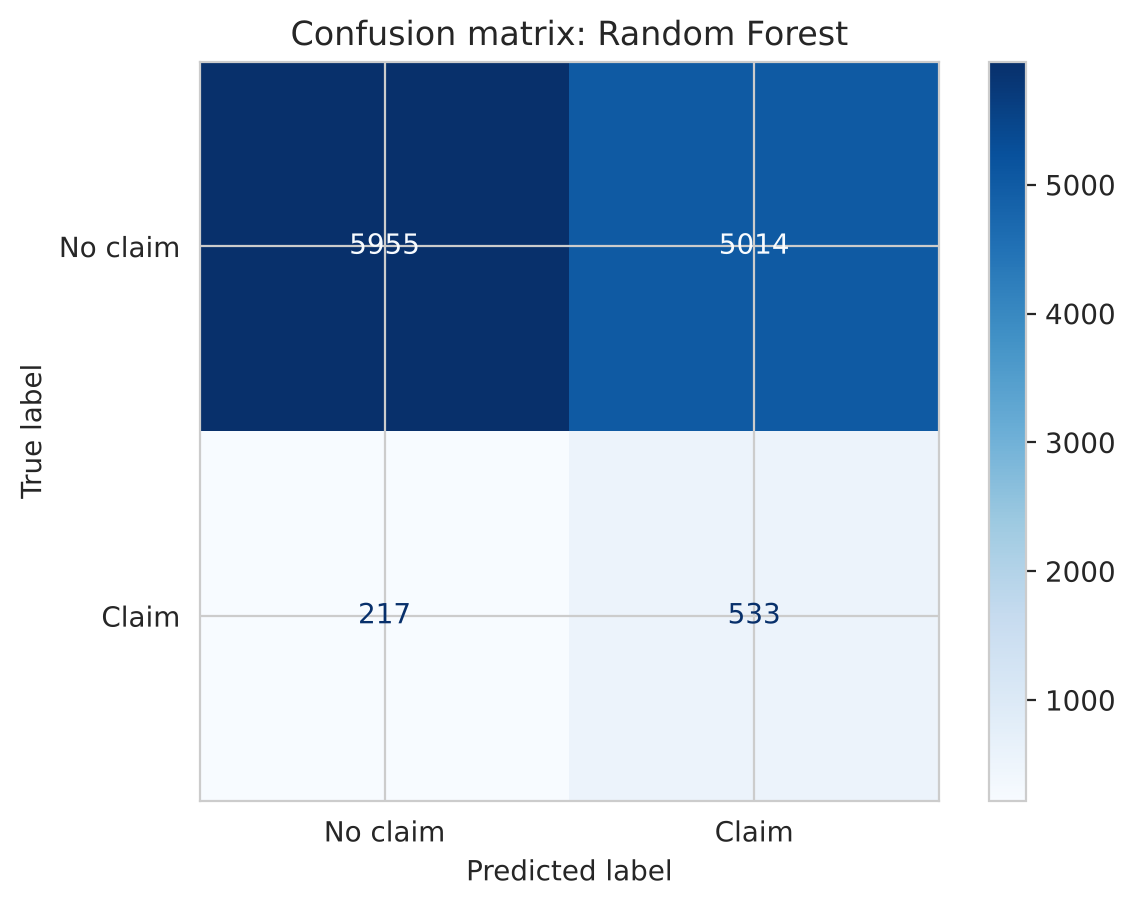

In [28]:
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test,
                                      display_labels=["No claim", "Claim"], cmap="Blues")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

### Step 10.4: The threshold trade-off
The 0.5 cut-off is only a default. Lowering it flags more policies (catching more real claims, but with more false alarms); raising it flags fewer (fewer false alarms, but more missed claims). The table shows how **recall** and **precision** change for the best model. Choose the threshold that suits the business: for example, an insurer that wants to review risky policies may accept many false alarms in return for catching more claims.

In [29]:
probs_best = best_model.predict_proba(X_test)[:, 1]

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (probs_best >= t).astype(int)
    rows.append({"threshold": t,
                 "flagged_%": round(pred_t.mean() * 100, 1),
                 "recall": round(recall_score(y_test, pred_t), 3),
                 "precision": round(precision_score(y_test, pred_t, zero_division=0), 3)})
pd.DataFrame(rows)

,threshold,flagged_%,recall,precision
0,0.3,92.3,0.972,0.067
1,0.4,70.8,0.881,0.080
2,0.5,47.3,0.711,0.096
3,0.6,6.4,0.123,0.123
4,0.7,0.0,0.000,0.000


### Step 10.5: Which features did the model use most?
Tree models can report **feature importance**: how much each input was used to make splits. They add up to 1.

- `best_model.feature_importances_` is a list of scores, one per column of `X_train`.
- `pd.Series(..., index=X_train.columns)` attaches the column names, and `.sort_values(ascending=False)` ranks them.

Remember: importance says what the model *used*, not whether a feature *raises or lowers* risk. And when two columns carry the same information (like `model_M4` and a feature that only M4 has), the credit gets split between them.

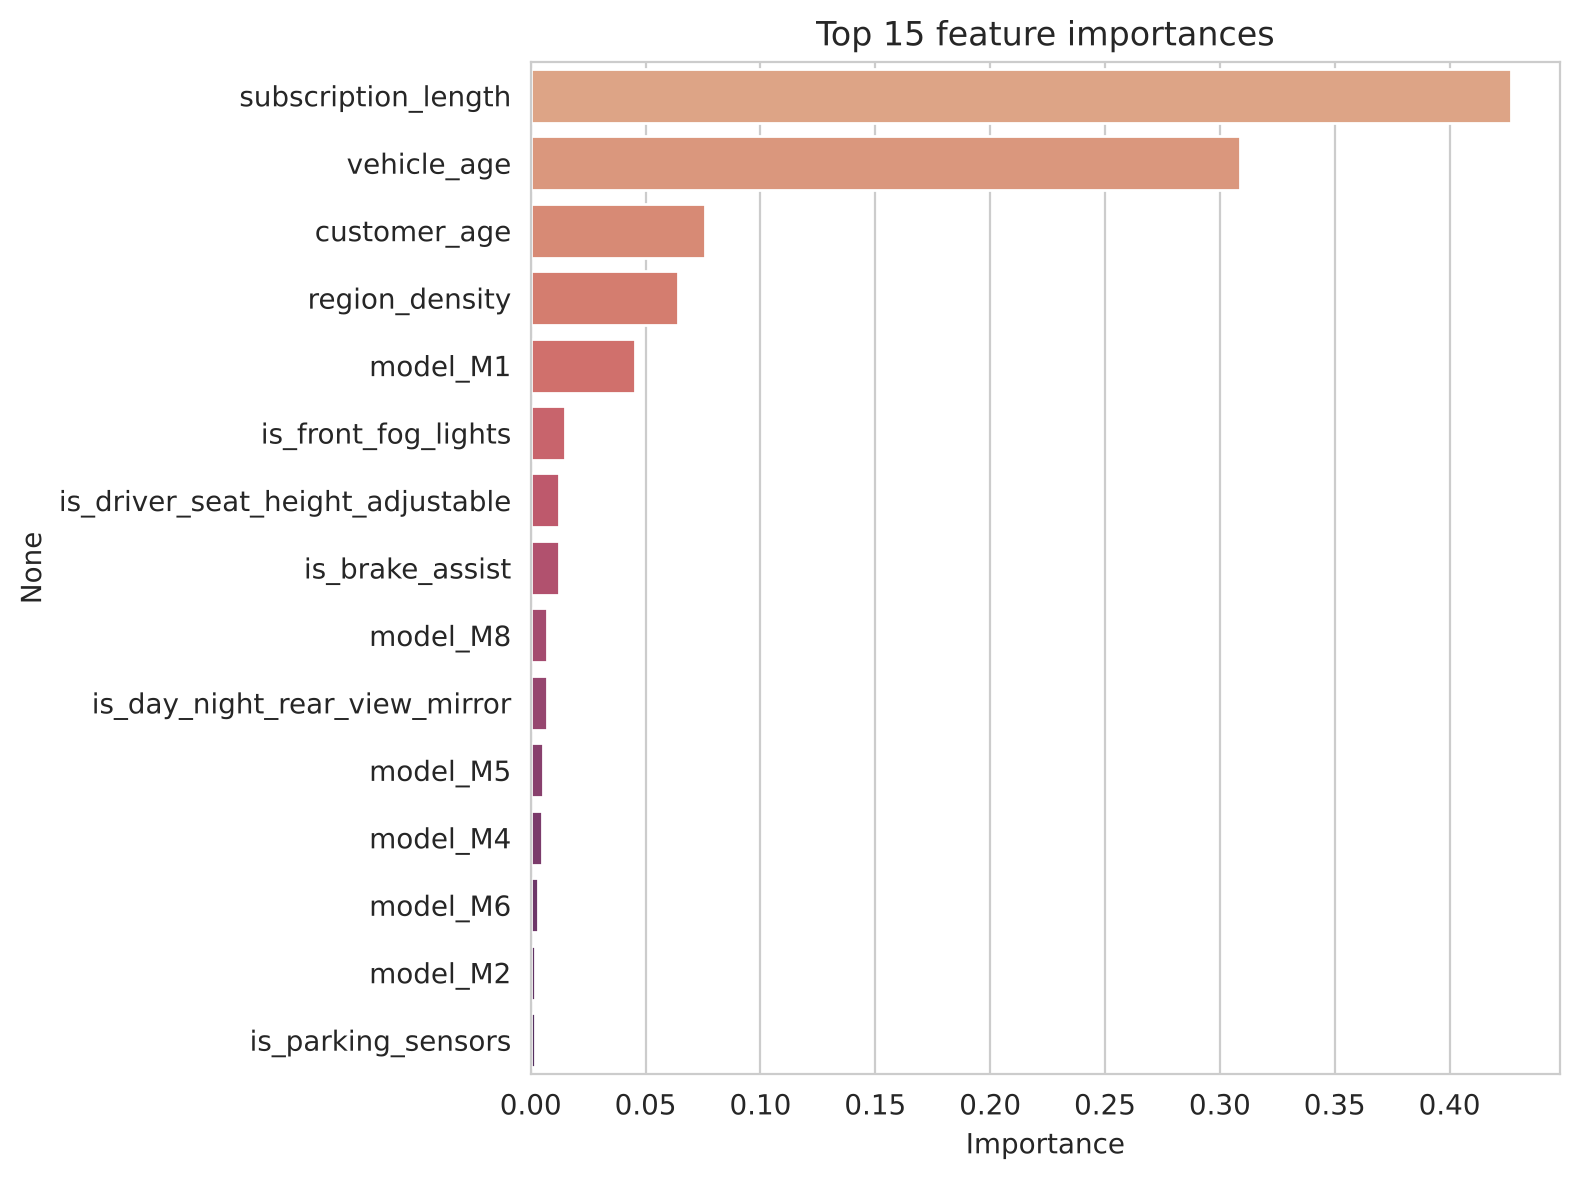

In [30]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top = importances.head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, hue=top.index, palette="flare", legend=False)
plt.title("Top 15 feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Results summary: what did we learn?

| Model | ROC-AUC |
|---|---|
| Decision Tree | 0.648 |
| **Random Forest (best)** | **0.662** |
| XGBoost | 0.658 |

*(Numbers can differ slightly on your computer.)*

### How to read these results honestly
- **All three models score about 0.65.** That is better than random guessing (0.5) but far from strong. The three models are very close, so the choice between them matters less than it looks.
- This matches the EDA: all the correlations with `claim_status` were tiny, so there is not much signal in this data. **A weak result here does not mean you made a mistake.** Insurance claims are hard to predict from this kind of information.
- At the default threshold of 0.5, the Random Forest **catches about 71% of real claims** but also flags about **47% of all policies**, so only about **9.6%** of the flagged policies really claim. That is still better than the 6.4% you would get by picking policies at random (roughly 1.5 times better), but it is a lot of false alarms. This is the cost of choosing to catch claims. It is also why overall accuracy (about 55%) is low and not a good number to judge by.
- In the threshold table the model's scores are squeezed into a narrow range: at 0.6 it flags only 6.4% of policies and at 0.7 it flags none. So in practice there is not much room to choose a threshold.

### Which features mattered?
- **`subscription_length`** (about 43% of the total importance) and **`vehicle_age`** (about 31%) dominate. This agrees with the EDA, where `subscription_length` had the strongest link to claims. Interestingly, `vehicle_age` had a weak *straight-line* correlation, but the trees found a non-linear pattern in it.
- `customer_age`, `region_density` and one car model (`model_M1`) come next.
- The seven Yes/No features add very little. As we found in Step 4.8, they are decided by the car model, so they repeat information we already have.

### ⚠️ Read the app's number as a *risk score*, not a true probability
Because we trained with `class_weight="balanced"`, the model's outputs are pushed upwards. A score of 50% from the app does **not** mean a 50% chance of a claim (the real average is 6.4%). Use it to **compare** policies (higher score = relatively riskier), not as an exact percentage.

### Ideas to improve it later
1. Tune the settings (`max_depth`, `n_estimators`, `learning_rate`) with cross-validation.
2. Create new features, such as customer-age groups or `subscription_length` bands.
3. Try removing the seven Yes/No columns, since they repeat `model`, and compare the scores.
4. Try adding `region_code` back with a proper encoding.

## Part 11: Save the model for the app

A trained model only lives in memory while the notebook runs. `joblib.dump(object, "file.pkl")` writes it to a file so another program (our web app) can load it later with `joblib.load`.

We save **three** things:
1. **`claim_model.pkl`**: the trained model.
2. **`model_columns.pkl`**: the exact column names and order used in training. The app must give the model its inputs in *this same order*, otherwise the predictions will be wrong.
3. **`model_options.pkl`**: the list of car models for the drop-down.

In [31]:
joblib.dump(best_model, "claim_model.pkl")
joblib.dump(X_train.columns.tolist(), "model_columns.pkl")
joblib.dump(model_options, "model_options.pkl")

print("Saved 3 files:", [f for f in ["claim_model.pkl", "model_columns.pkl", "model_options.pkl"]])
print("First columns:", X_train.columns.tolist()[:6])

Saved 3 files: ['claim_model.pkl', 'model_columns.pkl', 'model_options.pkl']
First columns: ['subscription_length', 'vehicle_age', 'customer_age', 'region_density', 'is_parking_sensors', 'is_front_fog_lights']


## Part 12: The Streamlit web app

**Streamlit** turns a Python script into a web page. Every time the user changes an input, the whole script runs again from top to bottom. The pieces:

| Code | What it shows |
|---|---|
| `st.title`, `st.write` | Headings and text |
| `st.slider`, `st.number_input` | Number inputs |
| `st.selectbox` | A drop-down list |
| `st.checkbox` | A tick box (returns `True`/`False`) |
| `st.columns(2)` | Puts things side by side |
| `st.button` | A button, which is `True` only on the run right after the click |
| `st.metric`, `st.error`, `st.success` | Display the result |

### How the app makes a prediction
1. Gather every input into a dictionary (checkbox `True/False` → `int` 1/0).
2. Turn it into a one-row table (`pd.DataFrame([input_dict])`).
3. Create the one-hot `model_...` columns by hand: 1 for the chosen car, 0 for the others.
4. `reindex(columns=model_columns, fill_value=0)` makes the row have **exactly the training columns in the training order**.
5. `model.predict_proba(...)` gives the claim probability.

All the prediction code lives **inside** `if st.button(...):` so that it only runs when the button is clicked. The next cell writes the app to a file called `app.py` (the `%%writefile` line is a Jupyter command that saves the cell's text to a file).

In [32]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import warnings
warnings.filterwarnings("ignore")

# Load the three files saved by the notebook
model = joblib.load("claim_model.pkl")
model_columns = joblib.load("model_columns.pkl")
model_options = joblib.load("model_options.pkl")

# The probability above which we flag a policy as higher risk.
# 0.5 is the default; change it using the threshold table in the notebook (Step 10.4).
THRESHOLD = 0.5

st.set_page_config(page_title="Insurance Claim Predictor", page_icon="🚗", layout="centered")
st.title("🚗 Insurance Claim Risk Predictor")
st.write("Fill in the policy and vehicle details below to estimate the probability "
         "that this policyholder will file a claim.")
st.divider()

col1, col2 = st.columns(2)

with col1:
    subscription_length = st.slider("Subscription length (years)", 0.0, 14.0, 5.7, step=0.1)
    vehicle_age = st.slider("Vehicle age (years)", 0.0, 20.0, 1.2, step=0.1)
    customer_age = st.slider("Customer age", 35, 75, 44)
    region_density = st.number_input("Region population density", min_value=0, max_value=80000,
                                     value=8794, step=100)

with col2:
    vehicle_model = st.selectbox("Vehicle model", model_options)
    is_parking_sensors = st.checkbox("Has parking sensors", value=True)
    is_front_fog_lights = st.checkbox("Has front fog lights", value=True)
    is_brake_assist = st.checkbox("Has brake assist", value=True)
    is_power_steering = st.checkbox("Has power steering", value=True)
    is_driver_seat_height_adjustable = st.checkbox("Driver seat height adjustable", value=True)
    is_day_night_rear_view_mirror = st.checkbox("Day/night rear-view mirror", value=True)
    is_speed_alert = st.checkbox("Has speed alert", value=True)

st.divider()

if st.button("Predict claim risk", type="primary"):

    # 1. gather the inputs (checkbox True/False -> 1/0)
    input_dict = {
        "subscription_length": subscription_length,
        "vehicle_age": vehicle_age,
        "customer_age": customer_age,
        "region_density": region_density,
        "is_parking_sensors": int(is_parking_sensors),
        "is_front_fog_lights": int(is_front_fog_lights),
        "is_brake_assist": int(is_brake_assist),
        "is_power_steering": int(is_power_steering),
        "is_driver_seat_height_adjustable": int(is_driver_seat_height_adjustable),
        "is_day_night_rear_view_mirror": int(is_day_night_rear_view_mirror),
        "is_speed_alert": int(is_speed_alert),
    }

    # 2. one-row table
    input_df = pd.DataFrame([input_dict])

    # 3. one-hot encode the chosen car model by hand
    for col in model_columns:
        if col.startswith("model_"):
            input_df[col] = 1 if col == f"model_{vehicle_model}" else 0

    # 4. same columns, same order as in training
    input_df = input_df.reindex(columns=model_columns, fill_value=0)

    # 5. predict
    proba = model.predict_proba(input_df)[0][1]

    st.subheader("Result")
    st.metric("Estimated claim risk score", f"{proba * 100:.1f}%")
    st.caption("This is a relative risk score (the model was trained with class balancing), "
               "not an exact probability. Use it to compare policies.")

    if proba >= THRESHOLD:
        st.error("⚠️ This policy is flagged as HIGHER risk of a claim.")
    else:
        st.success("✅ This policy is flagged as LOWER risk of a claim.")

    st.progress(min(max(float(proba), 0.0), 1.0))

Writing app.py


### Run the app
1. Make sure `app.py`, `claim_model.pkl`, `model_columns.pkl` and `model_options.pkl` are all in the **same folder**.
2. Open a terminal **in that folder** and run (do not use `python app.py`):

```
streamlit run app.py
```
3. If `streamlit` is not recognized, use `python -m streamlit run app.py`. If the module is missing, run `python -m pip install streamlit` first.
4. Stop the app with `Ctrl + C`.

## Cheat sheet

### Common errors seen in this project and their fixes
| Error | Cause | Fix |
|---|---|---|
| `FileNotFoundError` for the CSV | Notebook and CSV are in different folders, or the name differs | Put them together, or set `CSV_PATH` |
| `KeyError: 'region'` after re-running a cell | A previous run already replaced that column (for example by `get_dummies`) | **Restart, then Run All** |
| Columns become `NaN` after `.map(...)` | Values not in the dictionary, or the cell ran twice | Check `.unique()`, use the safe mapping in Step 7.1 |
| `df = df[col].map(...)` then `KeyError` | Assigned a single column over the whole table | Assign back to the column: `df[col] = df[col].map(...)` |
| `sort_values(...)` seems to do nothing | The sorted copy was not saved | `df = df.sort_values(...)` |
| `NotFittedError` | Called `predict` before `fit` | Run the training cell first |
| `NameError: name 'st' is not defined` | Running Streamlit code in plain Python | Use `streamlit run app.py` |

### Glossary
- **Feature:** an input column the model learns from.
- **Target / label:** the column we want to predict (`claim_status`).
- **Imbalanced data:** one class is much rarer than the other.
- **Overfitting:** the model memorizes the training data and performs worse on new data.
- **One-hot encoding:** turning a category into one 0/1 column per value.
- **Threshold:** the probability above which we say "claim".
- **Precision / recall:** how many flagged policies are real claims / how many real claims we caught.
- **ROC-AUC:** how well the model ranks risky policies above safe ones (0.5 = chance, 1 = perfect).
- **Data leakage:** accidentally letting information from the test set influence training.